### Installing required libraries

In [159]:
# Install required libraries
!pip install seaborn missingno xgboost catboost regex scikit-learn pandas numpy imblearn lightgbm polars


### Importing all libraries 

In [160]:
# Core libraries
import pandas as pd
import numpy as np
import csv
import re

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

# Preprocessing
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.utils import resample

# Model selection
from sklearn.model_selection import (
    train_test_split,
    cross_validate,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV
)

# Models
from sklearn.linear_model import LogisticRegression, LinearRegression, SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import LinearSVC
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import xgboost as xgb

# Metrics
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    make_scorer
)


### Import additional items as needed...

In [161]:
# Model selection utilities
from sklearn.model_selection import (
    KFold,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_score
)

# Preprocessing & pipelines
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PowerTransformer
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.pipeline import Pipeline
from imblearn.pipeline import make_pipeline

# Models & balancing
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from imblearn.over_sampling import SMOTE

# Metrics (only those not already imported in Script 2)
from sklearn.metrics import (
    confusion_matrix,
    balanced_accuracy_score,
    f1_score
)

# Plotly visualization
import plotly
import plotly.express as px
import plotly.graph_objs as go
import plotly.offline as py
from plotly.offline import iplot
from plotly.subplots import make_subplots
import plotly.figure_factory as ff

# Suppress warnings
import warnings
warnings.filterwarnings("ignore")


### Loading CSV data 

In [162]:
# Load dataset
diabetes = pd.read_csv('raw/diabetic_data.csv')


# DATA EXPLORATION

In [163]:
diabetes.head(30)

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO
5,35754,82637451,Caucasian,Male,[50-60),?,2,1,2,3,...,No,Steady,No,No,No,No,No,No,Yes,>30
6,55842,84259809,Caucasian,Male,[60-70),?,3,1,2,4,...,No,Steady,No,No,No,No,No,Ch,Yes,NO
7,63768,114882984,Caucasian,Male,[70-80),?,1,1,7,5,...,No,No,No,No,No,No,No,No,Yes,>30
8,12522,48330783,Caucasian,Female,[80-90),?,2,1,4,13,...,No,Steady,No,No,No,No,No,Ch,Yes,NO
9,15738,63555939,Caucasian,Female,[90-100),?,3,3,4,12,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [164]:
diabetes.shape

(101766, 50)

In [165]:
diabetes.columns

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted'],
      dtype='str')

In [166]:
diabetes.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


In [167]:
# placing the percentage of missing values in each column in a dataframe
missing_pct = (diabetes.isna()
                          .mean()
                          .mul(100)
                          .round(2)
                         # .sort_values(ascending=False)  #remove the # to sort by percentage of missing values in descending order
                          .reset_index())

missing_pct.columns = ["column", "percent_missing"]
missing_pct

,column,percent_missing
0,encounter_id,0.00
1,patient_nbr,0.00
2,race,0.00
3,gender,0.00
4,age,0.00
5,weight,0.00
6,admission_type_id,0.00
7,discharge_disposition_id,0.00
8,admission_source_id,0.00
9,time_in_hospital,0.00


<Axes: >

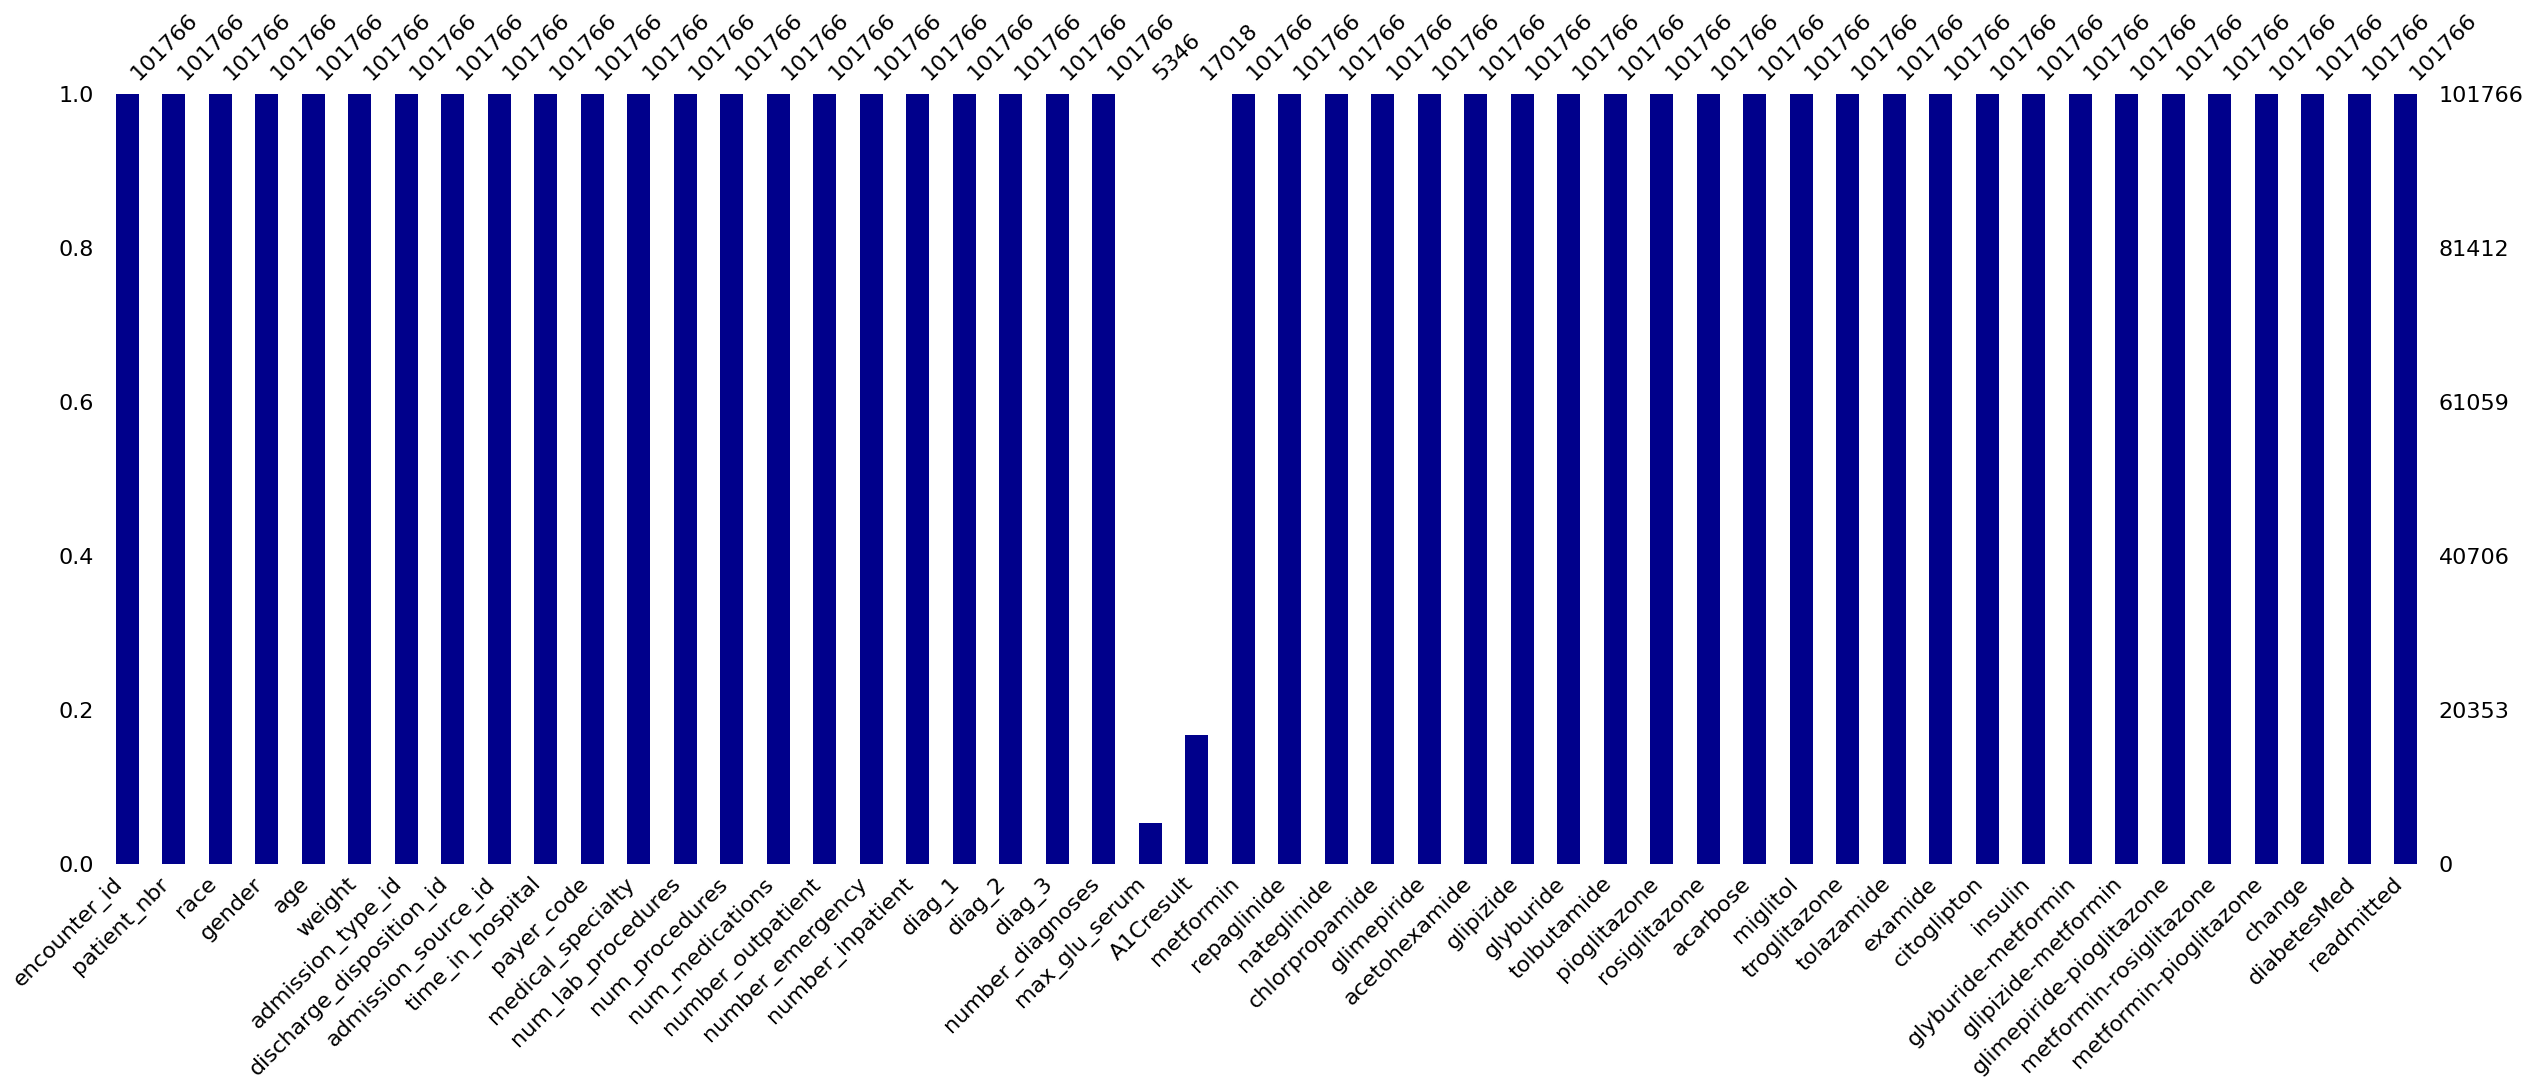

In [168]:
# visualizing the percentage of missing values in each column
msno.bar(diabetes, figsize=(30, 10), color='darkblue')

In [169]:
# Number of unique patients
unique_patients = diabetes['patient_nbr'].nunique()
print(f"Number of unique patients: {unique_patients}")

# Number of unique hospital encounters
unique_encounters = diabetes['encounter_id'].nunique()
print(f"Total number of hospital admissions: {unique_encounters}")

# Count admissions per patient
admissions_per_patient = (
    diabetes['patient_nbr']
    .value_counts()
    .rename_axis('patient_nbr')
    .reset_index(name='admission_count')
)

# Patients with more than one admission
multiple_admissions = admissions_per_patient.query("admission_count > 1")

# Proportion of patients with multiple admissions
prop_multiple = multiple_admissions['patient_nbr'].nunique() / unique_patients
print(f"Proportion of patients that have multiple admissions: {prop_multiple:.2%}")

# Maximum number of admissions for any patient
max_admissions = admissions_per_patient['admission_count'].max()
print(f"Highest number of admissions recorded for a single patient: {max_admissions}")

Number of unique patients: 71518
Total number of hospital admissions: 101766
Proportion of patients that have multiple admissions: 23.45%
Highest number of admissions recorded for a single patient: 40


# MAIN VARIABLE SELECTION

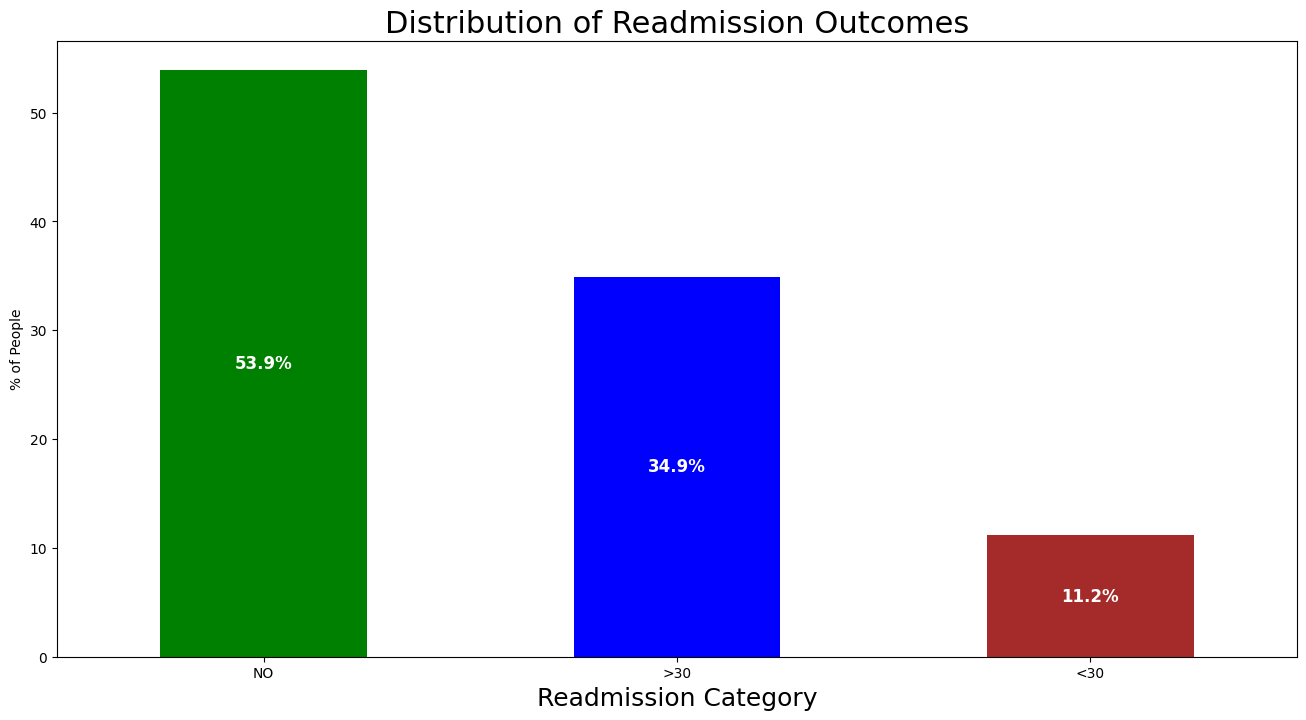

In [170]:
# Distribution of the readmitted variable
df_outcome = diabetes["readmitted"].value_counts(normalize=True) * 100

# Plot distribution
plt.figure(figsize=(16, 8))
ax = df_outcome.plot(
    kind='bar',
    stacked=True,
    color=['green', 'blue', 'brown']
)

plt.ylabel('% of People')
plt.xlabel('Readmission Category', fontsize=18)
plt.title('Distribution of Readmission Outcomes', fontsize=22)
plt.xticks(rotation=0)

# Add % labels inside each bar
for i, value in enumerate(df_outcome):
    ax.text(
        i,
        value / 2,
        f"{value:.1f}%",
        ha='center',
        va='center',
        color='white',
        fontsize=12,
        fontweight='bold'
    )

plt.show()


In [171]:
# Encode readmission: 1 = <30 days, 0 = otherwise
readmitted_map = {
    "NO": 0,
    "<30": 1,
    ">30": 0
}

# Create a new binary target column
diabetes['lessthan30'] = diabetes['readmitted'].map(readmitted_map)

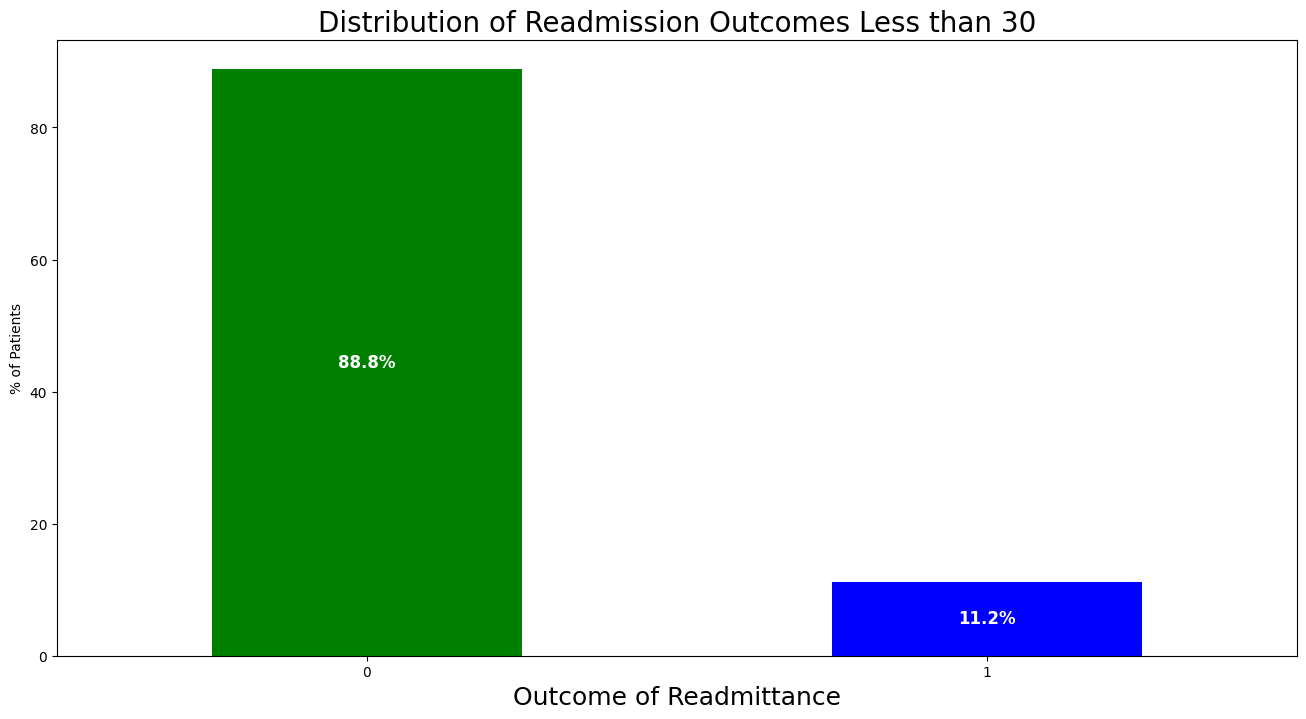

In [172]:
# Distribution of the readmitted variable
df_outcome = diabetes["lessthan30"].value_counts(normalize=True) * 100

# Plot
plt.figure(figsize=(16, 8))
ax = df_outcome.plot(
    kind='bar',
    color=['green', 'blue'], 
    stacked=True,
    figsize=(16, 8)
)

plt.xlabel('Outcome of Readmittance', fontsize=18)
plt.ylabel('% of Patients')
plt.title('Distribution of Readmission Outcomes Less than 30', fontsize=20)
plt.xticks(rotation=0)

# Add % labels inside each bar
for i, value in enumerate(df_outcome):
    ax.text(
        i,                      # x-position (bar index)
        value / 2,              # y-position (middle of the bar)
        f"{value:.1f}%",        # label text
        ha='center', va='center',
        color='white', fontsize=12, fontweight='bold'
    )

plt.show()

# CLEANING AND TRANSFORMING THE DATASET

In [173]:
#Mapping Admission Type ID, discharge disposition ID, and admission source ID to more interpretable categories
admission_type_map = {
    1: "Emergency",
    2: "Urgent",
    3: "Elective",
    4: "Newborn",
    5: "NotAvailable",
    6: "NULL",
    7: "TraumaCenter",
    8: "NotMapped"
}

discharge_disposition_map = {
    1: "Home",
    2: "ShortTermHospital",
    3: "SNF",
    4: "ICF",
    5: "OtherInpatientCare",
    6: "HomeHealth",
    7: "LeftAMA",
    8: "HomeIVCare",
    9: "AdmittedToThisHospital",
    10: "NeonateToAnotherHospital",
    11: "Expired",
    12: "StillPatient",
    13: "HospiceHome",
    14: "HospiceFacility",
    15: "SwingBed",
    16: "OutpatientServicesOtherInstitution",
    17: "OutpatientServicesThisInstitution",
    18: "NULL",
    19: "ExpiredHomeMedicaid",
    20: "ExpiredFacilityMedicaid",
    21: "ExpiredUnknownMedicaid",
    22: "RehabFacility",
    23: "LongTermCareHospital",
    24: "MedicaidNursingFacility",
    25: "NotMapped",
    26: "UnknownInvalid",
    27: "FederalHealthCareFacility",
    28: "PsychiatricHospital",
    29: "CriticalAccessHospital",
    30: "OtherHealthcareInstitution"
}

admission_source_map = {
    1: "PhysicianReferral",
    2: "ClinicReferral",
    3: "HMOReferral",
    4: "TransferHospital",
    5: "TransferSNF",
    6: "TransferOtherFacility",
    7: "EmergencyRoom",
    8: "CourtLaw",
    9: "NotAvailable",
    10: "TransferCAH",
    11: "NormalDelivery",
    12: "PrematureDelivery",
    13: "SickBaby",
    14: "ExtramuralBirth",
    15: "NotAvailable2",
    17: "NULL",
    18: "TransferHomeHealthAgency",
    19: "ReadmissionSameHomeHealthAgency",
    20: "NotMapped",
    21: "UnknownInvalid",
    22: "TransferSameFacility",
    23: "BornInsideHospital",
    24: "BornOutsideHospital",
    25: "TransferAmbulatorySurgery",
    26: "TransferHospice"
}


In [174]:
# Encode gender: keep only Male and Female
diabetes = diabetes[diabetes['gender'].isin(['Male', 'Female'])].copy()

# Create binary indicator: 1 = Male, 0 = Female
diabetes['GenderMale'] = (diabetes['gender'] == 'Male').astype(int)

In [175]:
#@title AGE ENCODING
# Convert everything to string and strip spaces
diabetes['age'] = diabetes['age'].astype(str).str.strip()

# Mapping age ranges to numeric midpoint values
age_map = {
    '[0-10)': 5,
    '[10-20)': 15,
    '[20-30)': 25,
    '[30-40)': 35,
    '[40-50)': 45,
    '[50-60)': 55,
    '[60-70)': 65,
    '[70-80)': 75,
    '[80-90)': 85,
    '[90-100)': 95
}

# Apply mapping
diabetes['age'] = diabetes['age'].map(age_map)

In [176]:
#@title # Encode diabetes medication: 1 = Yes, 0 = No
diabetes['diabetesMed'] = diabetes['diabetesMed'].apply(lambda x: 0 if x == "No" else 1)


In [177]:
# Encode race categories
diabetes['RaceCaucasian'] = (diabetes['race'] == 'Caucasian').astype(int)
diabetes['RaceAfricanAmerican'] = (diabetes['race'] == 'AfricanAmerican').astype(int)
diabetes['RaceOther'] = (~diabetes['race'].isin(['Caucasian', 'AfricanAmerican'])).astype(int)


In [178]:
#@title # Categorize ICD-9 codes into major diagnostic chapters
def clean_icd9(code):
    if pd.isna(code):
        return None

    code = str(code).strip()

    # Remove leading/trailing spaces
    if code == "" or code == "?":
        return None

    # Handle V-codes (supplementary classification)
    if code.startswith("V"):
        return 1000  # put V-codes in their own bucket

    # Handle E-codes (external causes)
    if code.startswith("E"):
        return 1100  # put E-codes in their own bucket

    # Try converting to integer
    try:
        return int(float(code))
    except:
        return None


In [179]:
chapter_map = {
    range(1, 140): "Infectious and Parasitic Diseases",
    range(140, 240): "Neoplasms",
    range(240, 280): "Endocrine/Metabolic",
    range(280, 290): "Blood Diseases",
    range(290, 320): "Mental Disorders",
    range(320, 390): "Nervous System",
    range(390, 460): "Circulatory System",
    range(460, 520): "Respiratory System",
    range(520, 580): "Digestive System",
    range(580, 630): "Genitourinary System",
    range(630, 680): "Pregnancy/Childbirth",
    range(680, 710): "Skin/Subcutaneous",
    range(710, 740): "Musculoskeletal",
    range(740, 760): "Congenital Anomalies",
    range(760, 780): "Perinatal Conditions",
    range(780, 800): "Symptoms/Ill-defined",
    range(800, 1000): "Injury/Poisoning"
}


In [180]:
def map_icd9_to_chapter(code):
    if code is None:
        return "Unknown"

    # V-codes
    if code == 1000:
        return "V-Codes"

    # E-codes
    if code == 1100:
        return "E-Codes"

    for r, chapter in chapter_map.items():
        if code in r:
            return chapter

    return "Unknown"


In [181]:
for col in ["diag_1", "diag_2", "diag_3"]:
    diabetes[col + "_clean"] = diabetes[col].apply(clean_icd9)
    diabetes[col + "_chapter"] = diabetes[col + "_clean"].apply(map_icd9_to_chapter)


In [182]:
df = pd.get_dummies(diabetes,
                    columns=["diag_1_chapter", "diag_2_chapter", "diag_3_chapter"],
                    drop_first=True)


In [183]:
diabetes.columns

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted',
       'lessthan30', 'GenderMale', 'RaceCaucasian', 'RaceAfricanAmerican',
       'RaceOther

In [184]:
diabetes["admission_type_id"] = diabetes["admission_type_id"].map({
    1: 1,  # Emergency
    2: 1,  # Urgent
    7: 1,  # TraumaCenter

    3: 0,  # Elective
    4: 0,  # Newborn
    5: 0,  # NotAvailable
    6: 0,  # NULL
    8: 0   # NotMapped
}).fillna(0).astype(int)

In [185]:
diabetes["discharge_disposition_id"] = (
    diabetes["discharge_disposition_id"]
        .map({
            # lower risk / routine discharge
            1: 0,   # Home
            6: 0,   # HomeHealth
            8: 0,   # HomeIVCare
            18: 0,  # NULL
            25: 0,  # NotMapped

            # higher risk / adverse outcomes
            2: 1,   # ShortTermHospital
            3: 1,   # SNF
            4: 1,   # ICF
            5: 1,   # OtherInpatientCare
            7: 1,   # LeftAMA
            9: 1,   # AdmittedToThisHospital
            10: 1,  # NeonateToAnotherHospital
            11: 1,  # Expired
            12: 1,  # StillPatient
            13: 1,  # HospiceHome
            14: 1,  # HospiceFacility
            15: 1,  # SwingBed
            16: 1,  # OutpatientServicesOtherInstitution
            17: 1,  # OutpatientServicesThisInstitution
            19: 1,  # ExpiredHomeMedicaid
            20: 1,  # ExpiredFacilityMedicaid
            22: 1,  # RehabFacility
            23: 1,  # LongTermCareHospital
            24: 1,  # MedicaidNursingFacility
            27: 1,  # FederalHealthCareFacility
            28: 1,  # PsychiatricHospital
            29: 1,  # CriticalAccessHospital
            30: 1   # OtherHealthcareInstitution
        })
        .fillna(0)
        .astype(int)
)

In [186]:
diabetes["admission_source_id"] = (
    diabetes["admission_source_id"]
        .astype(str)        # force pure string
        .str.strip()        # remove hidden whitespace
        .map({
            # higher‑risk / medical transfers
            "EmergencyRoom": 1,
            "TransferHospital": 1,
            "TransferSNF": 1,
            "TransferOtherFacility": 1,
            "TransferHomeHealthAgency": 1,
            "TransferSameFacility": 1,
            "TransferCAH": 1,
            "TransferAmbulatorySurgery": 1,
            "ReadmissionSameHomeHealthAgency": 1,

            # routine / lower‑risk
            "PhysicianReferral": 0,
            "ClinicReferral": 0,
            "HMOReferral": 0,
            "NormalDelivery": 0,
            "PrematureDelivery": 0,
            "SickBaby": 0,
            "BornInsideHospital": 0,
            "BornOutsideHospital": 0,
            "CourtLaw": 0,

            # unknown / administrative
            "NotAvailable": 0,
            "NotAvailable2": 0,
            "NotMapped": 0,
            "NULL": 0,
            "UnknownInvalid": 0
        })
        .fillna(0)           # safety catch
        .astype(int)
)


In [187]:
# ============================================================
# Binary mapping for ICD diagnosis chapters
# ============================================================

diag_binary_map = {
    # higher‑risk / chronic / severe
    "Endocrine/Metabolic": 1,
    "Circulatory System": 1,
    "Respiratory System": 1,
    "Neoplasms": 1,
    "Infectious and Parasitic Diseases": 1,
    "Injury/Poisoning": 1,
    "Genitourinary System": 1,
    "Nervous System": 1,
    "Blood Diseases": 1,
    "Mental Disorders": 1,

    # lower‑risk / administrative / vague
    "Symptoms/Ill-defined": 0,
    "Skin/Subcutaneous": 0,
    "Musculoskeletal": 0,
    "Digestive System": 0,
    "Pregnancy/Childbirth": 0,
    "Congenital Anomalies": 0,
    "V-Codes": 0,
    "E-Codes": 0,
    "Unknown": 0
}

# ============================================================
# Apply to all diagnosis chapter columns IN PLACE
# ============================================================

for col in ["diag_1_chapter", "diag_2_chapter", "diag_3_chapter"]:
    diabetes[col] = (
        diabetes[col]
            .astype(str)
            .str.strip()
            .map(diag_binary_map)
            .fillna(0)
            .astype(int)
    )

In [188]:
#@title # Drop unnecessary columns to create two cleaned datasets

# Dataset 1: drops A1Cresult and max_glu_serum
cleandiabetes1 = diabetes.drop([
    'race', 'weight', 'gender',
    'payer_code', 'medical_specialty',
    'diag_1', 'diag_2', 'diag_3',
    'max_glu_serum', 'A1Cresult',
    'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
    'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
    'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
    'tolazamide', 'examide', 'citoglipton', 'insulin',
    'glyburide-metformin', 'glipizide-metformin',
    'glimepiride-pioglitazone', 'metformin-rosiglitazone',
    'metformin-pioglitazone',
    'change', 'readmitted', 'diag_1_clean', 'diag_2_clean', 'diag_3_clean'
], axis=1)

# Dataset 2: keeps A1Cresult but still drops max_glu_serum
cleandiabetes2 = diabetes.drop([
    'race', 'weight', 'gender',
    'payer_code', 'medical_specialty',
    'diag_1', 'diag_2', 'diag_3',
    'max_glu_serum',
    'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
    'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
    'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
    'tolazamide', 'examide', 'citoglipton', 'insulin',
    'glyburide-metformin', 'glipizide-metformin',
    'glimepiride-pioglitazone', 'metformin-rosiglitazone',
    'metformin-pioglitazone',
    'change', 'readmitted','diag_1_clean', 'diag_2_clean', 'diag_3_clean'
], axis=1)


In [189]:
cleandiabetes1.head()


,encounter_id,patient_nbr,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,...,number_diagnoses,diabetesMed,lessthan30,GenderMale,RaceCaucasian,RaceAfricanAmerican,RaceOther,diag_1_chapter,diag_2_chapter,diag_3_chapter
0,2278392,8222157,5,0,0,0,1,41,0,1,...,1,0,0,0,1,0,0,1,0,0
1,149190,55629189,15,1,0,0,3,59,0,18,...,9,1,0,0,1,0,0,1,1,1
2,64410,86047875,25,1,0,0,2,11,5,13,...,6,1,0,0,0,1,0,0,1,0
3,500364,82442376,35,1,0,0,2,44,1,16,...,7,1,0,1,1,0,0,1,1,1
4,16680,42519267,45,1,0,0,1,51,0,8,...,5,1,0,1,1,0,0,1,1,1


In [190]:
cleandiabetes2.head()

,encounter_id,patient_nbr,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,...,A1Cresult,diabetesMed,lessthan30,GenderMale,RaceCaucasian,RaceAfricanAmerican,RaceOther,diag_1_chapter,diag_2_chapter,diag_3_chapter
0,2278392,8222157,5,0,0,0,1,41,0,1,...,NaN,0,0,0,1,0,0,1,0,0
1,149190,55629189,15,1,0,0,3,59,0,18,...,NaN,1,0,0,1,0,0,1,1,1
2,64410,86047875,25,1,0,0,2,11,5,13,...,NaN,1,0,0,0,1,0,0,1,0
3,500364,82442376,35,1,0,0,2,44,1,16,...,NaN,1,0,1,1,0,0,1,1,1
4,16680,42519267,45,1,0,0,1,51,0,8,...,NaN,1,0,1,1,0,0,1,1,1


In [191]:
# Clean A1Cresult in cleandiabetes2
cleandiabetes2['A1Cresult'] = cleandiabetes2['A1Cresult'].replace('None', np.nan)

# Drop rows where A1Cresult is missing
cleandiabetes2 = cleandiabetes2.dropna(subset=['A1Cresult'])

# Encode A1C: Normal = 0, anything else = 1
cleandiabetes2['NumA1C'] = cleandiabetes2['A1Cresult'].apply(
    lambda x: 0 if x == 'Normal' else 1
)

# Remove the original A1Cresult column
cleandiabetes2 = cleandiabetes2.drop(columns=['A1Cresult'])

# Show remaining row count
print(f"Number of rows after removing 'None' A1Cresult values: {cleandiabetes2.shape[0]}")


Number of rows after removing 'None' A1Cresult values: 17018


### FINALIZING DATASET

In [192]:
# Unique and duplicate patient IDs for cleandiabetes1
unique_ids_1 = cleandiabetes1['patient_nbr'].unique()
duplicate_ids_1 = cleandiabetes1['patient_nbr'][cleandiabetes1['patient_nbr'].duplicated()].unique()

print("=== cleandiabetes1 ===")
print(f"Dataset size: {len(cleandiabetes1)}")
print(f"Unique patient IDs: {len(unique_ids_1)}")
print(f"Duplicate patient IDs: {len(duplicate_ids_1)}\n")


# Unique and duplicate patient IDs for cleandiabetes2
unique_ids_2 = cleandiabetes2['patient_nbr'].unique()
duplicate_ids_2 = cleandiabetes2['patient_nbr'][cleandiabetes2['patient_nbr'].duplicated()].unique()

print("=== cleandiabetes2 ===")
print(f"Dataset size: {len(cleandiabetes2)}")
print(f"Unique patient IDs: {len(unique_ids_2)}")
print(f"Duplicate patient IDs: {len(duplicate_ids_2)}")


=== cleandiabetes1 ===
Dataset size: 101763
Unique patient IDs: 71515
Duplicate patient IDs: 16773

=== cleandiabetes2 ===
Dataset size: 17018
Unique patient IDs: 15388
Duplicate patient IDs: 1259


In [193]:
# Columns to remove
cols_to_drop = ['encounter_id', 'patient_nbr']

# Apply to cleandiabetes1
subcleanDB1 = cleandiabetes1.drop(columns=cols_to_drop)

# Apply to cleandiabetes2
subcleanDB2 = cleandiabetes2.drop(columns=cols_to_drop)

print("Dropped encounter_id and patient_nbr from both datasets.")
print(f"subcleanDB1 shape: {subcleanDB1.shape}")
print(f"subcleanDB2 shape: {subcleanDB2.shape}")


Dropped encounter_id and patient_nbr from both datasets.
subcleanDB1 shape: (101763, 21)
subcleanDB2 shape: (17018, 22)


In [194]:
print("Columns in subcleanDB1:")
print(subcleanDB1.columns.tolist(), "\n")

print("Columns in subcleanDB2:")
print(subcleanDB2.columns.tolist())


Columns in subcleanDB1:
['age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'diabetesMed', 'lessthan30', 'GenderMale', 'RaceCaucasian', 'RaceAfricanAmerican', 'RaceOther', 'diag_1_chapter', 'diag_2_chapter', 'diag_3_chapter'] 

Columns in subcleanDB2:
['age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'diabetesMed', 'lessthan30', 'GenderMale', 'RaceCaucasian', 'RaceAfricanAmerican', 'RaceOther', 'diag_1_chapter', 'diag_2_chapter', 'diag_3_chapter', 'NumA1C']


In [195]:
numerical = ['age', 'time_in_hospital', 'num_lab_procedures', 'num_procedures',
       'num_medications', 'number_outpatient', 'number_emergency',
       'number_inpatient', 'number_diagnoses' ]

### MISSING DATA

In [196]:
def missing(df):
    missing_number = df.isnull().sum().sort_values(ascending=False)
    missing_percent = (df.isnull().sum() / len(df)).sort_values(ascending=False)

    return pd.concat(
        [missing_number, missing_percent],
        axis=1,
        keys=['Missing_Number', 'Missing_Percent']
    )


In [197]:
print("Missing values in subcleanDB1:")
display(missing(subcleanDB1))

print("\nMissing values in subcleanDB2:")
display(missing(subcleanDB2))


Missing values in subcleanDB1:


,Missing_Number,Missing_Percent
age,0,0.0
admission_type_id,0,0.0
discharge_disposition_id,0,0.0
admission_source_id,0,0.0
time_in_hospital,0,0.0
num_lab_procedures,0,0.0
num_procedures,0,0.0
num_medications,0,0.0
number_outpatient,0,0.0
number_emergency,0,0.0



Missing values in subcleanDB2:


,Missing_Number,Missing_Percent
age,0,0.0
admission_type_id,0,0.0
discharge_disposition_id,0,0.0
admission_source_id,0,0.0
time_in_hospital,0,0.0
num_lab_procedures,0,0.0
num_procedures,0,0.0
num_medications,0,0.0
number_outpatient,0,0.0
number_emergency,0,0.0


### VISUALING MISSING DATA

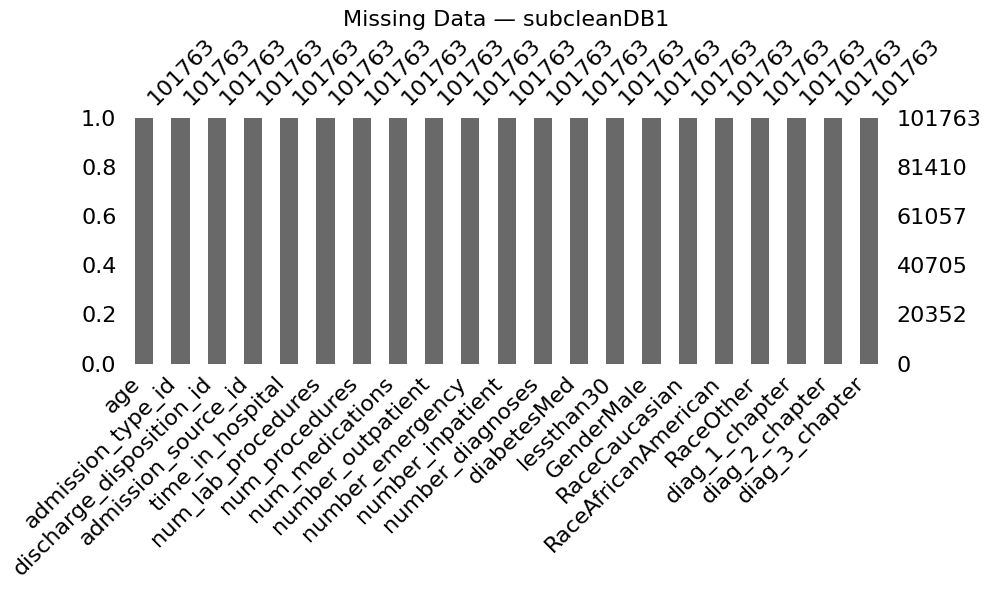

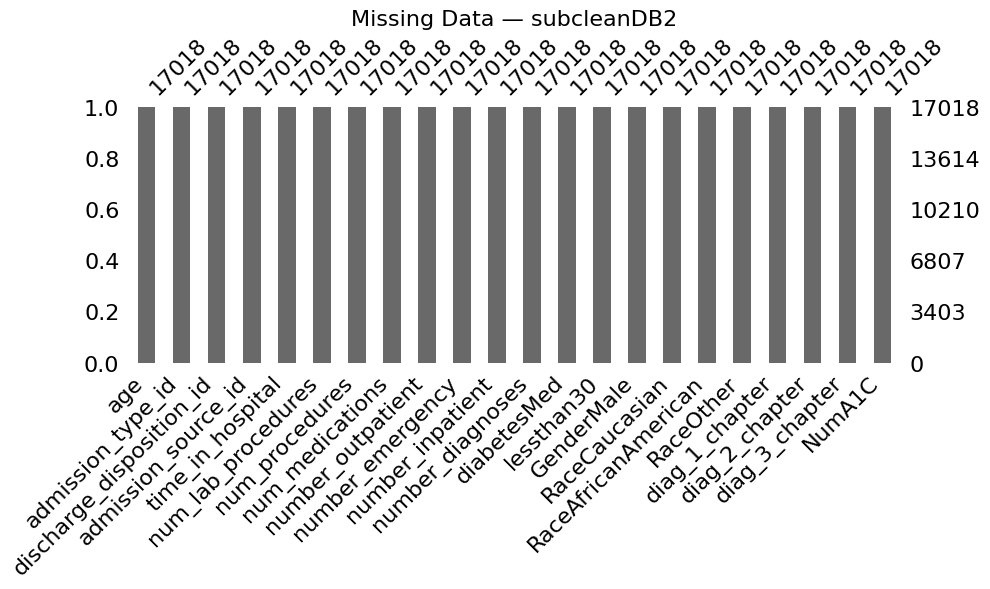

In [198]:
# Visualizing missing data for subcleanDB1
fig, ax = plt.subplots(figsize=(10, 6))
msno.bar(subcleanDB1, ax=ax)
ax.set_title("Missing Data — subcleanDB1", fontsize=16)
plt.tight_layout()
plt.show()

# Visualizing missing data for subcleanDB2
fig, ax = plt.subplots(figsize=(10, 6))
msno.bar(subcleanDB2, ax=ax)
ax.set_title("Missing Data — subcleanDB2", fontsize=16)
plt.tight_layout()
plt.show()


### CORRELATION

In [199]:
# Correlation matrix for subcleanDB1
print("Correlation Matrix for subcleanDB1")
display(subcleanDB1[numerical].corr())

# Correlation matrix for subcleanDB2
print("\nCorrelation Matrix for subcleanDB2")
display(subcleanDB2[numerical].corr())

Correlation Matrix for subcleanDB1


,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
age,1.000000,0.107516,0.020777,-0.030119,0.041839,0.023727,-0.087289,-0.042856,0.242609
time_in_hospital,0.107516,1.000000,0.318429,0.191497,0.466137,-0.008919,-0.009683,0.073619,0.220153
num_lab_procedures,0.020777,0.318429,1.000000,0.058105,0.268176,-0.007606,-0.002282,0.039225,0.152737
num_procedures,-0.030119,0.191497,0.058105,1.000000,0.385761,-0.024813,-0.038175,-0.066226,0.073769
num_medications,0.041839,0.466137,0.268176,0.385761,1.000000,0.045198,0.013180,0.064196,0.261529
number_outpatient,0.023727,-0.008919,-0.007606,-0.024813,0.045198,1.000000,0.091457,0.107334,0.094148
number_emergency,-0.087289,-0.009683,-0.002282,-0.038175,0.013180,0.091457,1.000000,0.266557,0.055536
number_inpatient,-0.042856,0.073619,0.039225,-0.066226,0.064196,0.107334,0.266557,1.000000,0.104703
number_diagnoses,0.242609,0.220153,0.152737,0.073769,0.261529,0.094148,0.055536,0.104703,1.000000



Correlation Matrix for subcleanDB2


,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
age,1.000000,0.141760,0.061713,0.033297,0.132112,0.048388,-0.074286,-0.031047,0.344831
time_in_hospital,0.141760,1.000000,0.343186,0.288662,0.514548,-0.018407,-0.024822,0.064948,0.216456
num_lab_procedures,0.061713,0.343186,1.000000,0.156745,0.326129,-0.003939,0.009600,0.011821,0.191567
num_procedures,0.033297,0.288662,0.156745,1.000000,0.477836,-0.026016,-0.033390,-0.034040,0.165271
num_medications,0.132112,0.514548,0.326129,0.477836,1.000000,0.065050,0.012794,0.071858,0.381430
number_outpatient,0.048388,-0.018407,-0.003939,-0.026016,0.065050,1.000000,0.092708,0.114571,0.109338
number_emergency,-0.074286,-0.024822,0.009600,-0.033390,0.012794,0.092708,1.000000,0.290177,0.072703
number_inpatient,-0.031047,0.064948,0.011821,-0.034040,0.071858,0.114571,0.290177,1.000000,0.104482
number_diagnoses,0.344831,0.216456,0.191567,0.165271,0.381430,0.109338,0.072703,0.104482,1.000000


In [200]:
#@title Correlation grouped by lessthan30 for subcleanDB1
# Automatically detect numeric columns
numeric_cols_1 = subcleanDB1.select_dtypes(include=['int64', 'float64']).columns

print("\nCorrelation for subcleanDB1 grouped by lessthan30")
corr_30_1 = subcleanDB1.groupby('lessthan30')[numeric_cols_1].corr()
display(corr_30_1)




Correlation for subcleanDB1 grouped by lessthan30


age  admission_type_id  \
lessthan30                                                         
0          age                       1.000000           0.018309   
           admission_type_id         0.018309           1.000000   
           discharge_disposition_id  0.277647           0.040556   
           admission_source_id            NaN                NaN   
           time_in_hospital          0.110389           0.021797   
           num_lab_procedures        0.023679           0.203607   
           num_procedures           -0.030493          -0.175892   
           num_medications           0.045632          -0.142405   
           number_outpatient         0.025841          -0.018663   
           number_emergency         -0.073725           0.031061   
           number_inpatient         -0.012439           0.049156   
           number_diagnoses          0.250586           0.109891   
           diabetesMed              -0.024204           0.001611   
           lessthan30                     NaN                NaN   
           GenderMale               -0.051911          -0.015835   
           RaceCaucasian             0.170076          -0.082366   
           RaceAfricanAmerican      -0.157756           0.087765   
           RaceOther                -0.049805           0.006035   
           diag_1_chapter            0.071068           0.066154   
           diag_2_chapter            0.084704           0.011825   
           diag_3_chapter            0.108517           0.008692   
1          age                       1.000000           0.006954   
           admission_type_id         0.006954           1.000000   
           discharge_disposition_id  0.249327          -0.015012   
           admission_source_id            NaN                NaN   
           time_in_hospital          0.078964           0.018040   
           num_lab_procedures       -0.006361           0.183362   
           num_procedures           -0.025012          -0.146603   
           num_medications           0.005392          -0.110765   
           number_outpatient         0.004394          -0.001626   
           number_emergency         -0.171721           0.025601   
           number_inpatient         -0.209974           0.038007   
           number_diagnoses          0.167476           0.105408   
           diabetesMed              -0.013679          -0.025452   
           lessthan30                     NaN                NaN   
           GenderMale               -0.039427          -0.022281   
           RaceCaucasian             0.167764          -0.083812   
           RaceAfricanAmerican      -0.176174           0.095329   
           RaceOther                -0.012958          -0.006249   
           diag_1_chapter            0.059648           0.101447   
           diag_2_chapter            0.080394           0.017229   
           diag_3_chapter            0.088080           0.012725   

                                     discharge_disposition_id  \
lessthan30                                                      
0          age                                       0.277647   
           admission_type_id                         0.040556   
           discharge_disposition_id                  1.000000   
           admission_source_id                            NaN   
           time_in_hospital                          0.195912   
           num_lab_procedures                        0.075818   
           num_procedures                           -0.044206   
           num_medications                           0.110901   
           number_outpatient                         0.027272   
           number_emergency                          0.005543   
           number_inpatient                          0.052769   
           number_diagnoses                          0.172783   
           diabetesMed                              -0.000496   
           lessthan30                                     NaN   
         

In [201]:
#@title Correlation grouped by lessthan30 for subcleanDB2
# Automatically detect numeric columns
numeric_cols_2 = subcleanDB2.select_dtypes(include=['int64', 'float64']).columns

print("\nCorrelation for subcleanDB2 grouped by lessthan30")
corr_30_2 = subcleanDB2.groupby('lessthan30')[numeric_cols_2].corr()
display(corr_30_2)



Correlation for subcleanDB2 grouped by lessthan30


age  admission_type_id  \
lessthan30                                                         
0          age                       1.000000           0.004746   
           admission_type_id         0.004746           1.000000   
           discharge_disposition_id  0.264259          -0.000929   
           admission_source_id            NaN                NaN   
           time_in_hospital          0.143550          -0.061397   
           num_lab_procedures        0.066070           0.016833   
           num_procedures            0.036809          -0.113500   
           num_medications           0.141206          -0.124984   
           number_outpatient         0.049269          -0.022816   
           number_emergency         -0.068360           0.020443   
           number_inpatient         -0.011523           0.020159   
           number_diagnoses          0.355707           0.006472   
           diabetesMed              -0.053778          -0.015077   
           lessthan30                     NaN                NaN   
           GenderMale               -0.056680          -0.004598   
           RaceCaucasian             0.164378          -0.048734   
           RaceAfricanAmerican      -0.164885           0.074411   
           RaceOther                -0.028124          -0.029458   
           diag_1_chapter            0.039025           0.048913   
           diag_2_chapter            0.107672           0.007266   
           diag_3_chapter            0.159359           0.012659   
           NumA1C                         NaN                NaN   
1          age                       1.000000           0.034710   
           admission_type_id         0.034710           1.000000   
           discharge_disposition_id  0.244881           0.003489   
           admission_source_id            NaN                NaN   
           time_in_hospital          0.109543          -0.002812   
           num_lab_procedures        0.008616           0.041103   
           num_procedures           -0.004521          -0.087306   
           num_medications           0.029641          -0.106318   
           number_outpatient         0.034561          -0.004691   
           number_emergency         -0.138689           0.045147   
           number_inpatient         -0.176794           0.034098   
           number_diagnoses          0.210427           0.080886   
           diabetesMed              -0.075994          -0.003154   
           lessthan30                     NaN                NaN   
           GenderMale               -0.070432          -0.022179   
           RaceCaucasian             0.157519          -0.046414   
           RaceAfricanAmerican      -0.181377           0.078651   
           RaceOther                 0.014404          -0.046161   
           diag_1_chapter            0.084338           0.049047   
           diag_2_chapter            0.108505           0.039496   
           diag_3_chapter            0.130273           0.040330   
           NumA1C                         NaN                NaN   

                                     discharge_disposition_id  \
lessthan30                                                      
0          age                                       0.264259   
           admission_type_id                        -0.000929   
           discharge_disposition_id                  1.000000   
           admission_source_id                            NaN   
           time_in_hospital                          0.176333   
           num_lab_procedures                        0.097698   
           num_procedures                            0.001860   
           num_medications                           0.133287   
           number_outpatient                         0.063103   
           number_emergency                          0.006809   
           number_inpatient                          0.022086   
           number_diagnoses                          0.178159   
   

| Color Range      | Intensity    | Correlation         | Meaning                                    |
| ---------------- | ------------ | ------------------- | ------------------------------------------ |
| Dark Red         | 0.6 to 1.0   | Strong positive     | Variables move together (both ↑ or both ↓) |
| Light Red/Orange | 0.2 to 0.6   | Moderate positive   | Variables tend to move together            |
| White/Pale       | -0.2 to +0.2 | Weak/No correlation | No linear relationship                     |
| Light Blue       | -0.2 to -0.6 | Moderate negative   | Variables move opposite (one ↑, other ↓)   |
| Dark Blue        | -0.6 to -1.0 | Strong negative     | Variables strongly oppose each other       |

|CORRELATION| ACTION                      |
|-----------|-----------------------------|
| ≥ +0.70   | Feature engineering/PCA     |
| +0.50-0.69| Keep both (important pair)  |
| +0.30-0.49| Moderate (conditional keep) |
| < ±0.30   | Weak (consider dropping)    |


In [203]:
#@title Reusable Correlation Heatmaps
def plot_corr_heatmap(df, numerical, title):
    """
    Plots a lower‑triangle correlation heatmap for a given dataframe.
    """
    corr_matrix = df[numerical].corr()

    # Mask upper triangle
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

    plt.figure(figsize=(10, 8))
    sns.heatmap(
        corr_matrix,
        annot=True,
        cmap='coolwarm',
        center=0,
        square=True,
        linewidths=0.5,
        fmt='.2f',
        mask=mask
    )

    plt.title(title, fontsize=14)
    plt.tight_layout()
    plt.show()


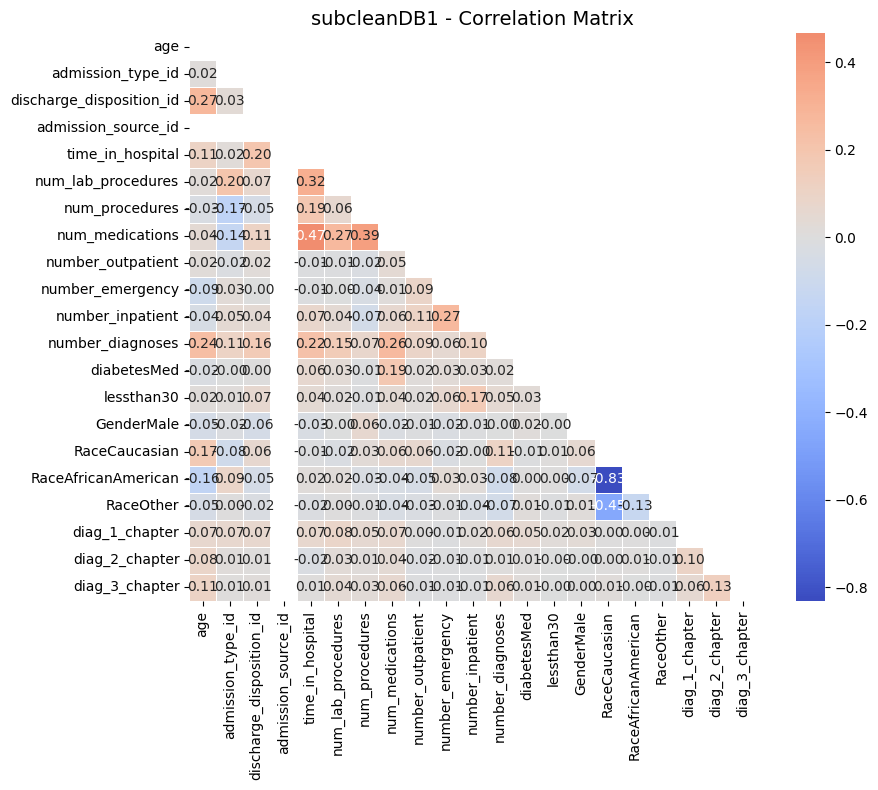

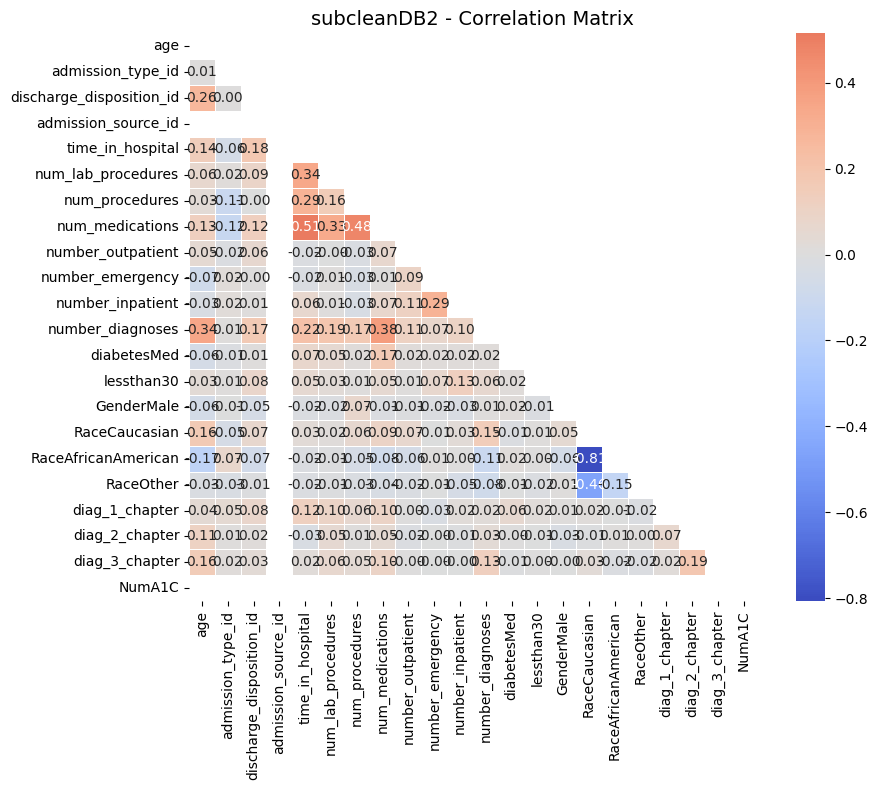

In [204]:
#@title Correlation Heatmaps for subcleanDB1 and subcleanDB2

# Detect numeric columns for each dataset
numeric_cols_1 = subcleanDB1.select_dtypes(include=['int64', 'float64']).columns
numeric_cols_2 = subcleanDB2.select_dtypes(include=['int64', 'float64']).columns

# Plot heatmap for subcleanDB1
plot_corr_heatmap(
    subcleanDB1,
    numeric_cols_1,
    "subcleanDB1 - Correlation Matrix"
)

# Plot heatmap for subcleanDB2
plot_corr_heatmap(
    subcleanDB2,
    numeric_cols_2,
    "subcleanDB2 - Correlation Matrix"
)


## Breaking the data up into Train & Test

In [205]:
#@title Setting Up Data for Modeling

# Create modeling copies for both datasets
DataTesting1 = subcleanDB1.copy()
DataTesting2 = subcleanDB2.copy()

print("DataTesting1 and DataTesting2 are ready for modeling.")
print(f"DataTesting1 shape: {DataTesting1.shape}")
print(f"DataTesting2 shape: {DataTesting2.shape}")


DataTesting1 and DataTesting2 are ready for modeling.
DataTesting1 shape: (101763, 21)
DataTesting2 shape: (17018, 22)


In [206]:
#@title Train / Validation / Test Split for Both Datasets

# Function to split any dataset into 70/15/15
def split_dataset(df):
    # Step 1: Train (70%) + Temp (30%)
    train_df, temp_df = train_test_split(
        df,
        test_size=0.30,
        random_state=42,
        shuffle=True
    )

    # Step 2: Validation (15%) + Test (15%)
    valid_df, test_df = train_test_split(
        temp_df,
        test_size=0.50,
        random_state=42,
        shuffle=True
    )

    # Step 3: Reset indexes
    return (
        train_df.reset_index(drop=True),
        valid_df.reset_index(drop=True),
        test_df.reset_index(drop=True)
    )


# Split DataTesting1
train1, valid1, test1 = split_dataset(DataTesting1)

# Split DataTesting2
train2, valid2, test2 = split_dataset(DataTesting2)


# Summary output
print("=== Dataset 1 Splits ===")
print("Train1 size:", len(train1))
print("Valid1 size:", len(valid1))
print("Test1 size:", len(test1))
print("Total:", len(train1) + len(valid1) + len(test1))

print("\n=== Dataset 2 Splits ===")
print("Train2 size:", len(train2))
print("Valid2 size:", len(valid2))
print("Test2 size:", len(test2))
print("Total:", len(train2) + len(valid2) + len(test2))


=== Dataset 1 Splits ===
Train1 size: 71234
Valid1 size: 15264
Test1 size: 15265
Total: 101763

=== Dataset 2 Splits ===
Train2 size: 11912
Valid2 size: 2553
Test2 size: 2553
Total: 17018


In [207]:
#@title Value Counts for lessthan30 (Both Datasets)

datasets = {
    "DataTesting1": DataTesting1,
    "Train1": train1,
    "Valid1": valid1,
    "Test1": test1,

    "DataTesting2": DataTesting2,
    "Train2": train2,
    "Valid2": valid2,
    "Test2": test2
}

for name, df in datasets.items():
    print(f"\n===== {name} Dataset =====")
    
    # lessthan30 counts only
    print("lessthan30:")
    print(df["lessthan30"].value_counts())



===== DataTesting1 Dataset =====
lessthan30:
lessthan30
0    90406
1    11357
Name: count, dtype: int64

===== Train1 Dataset =====
lessthan30:
lessthan30
0    63318
1     7916
Name: count, dtype: int64

===== Valid1 Dataset =====
lessthan30:
lessthan30
0    13519
1     1745
Name: count, dtype: int64

===== Test1 Dataset =====
lessthan30:
lessthan30
0    13569
1     1696
Name: count, dtype: int64

===== DataTesting2 Dataset =====
lessthan30:
lessthan30
0    15342
1     1676
Name: count, dtype: int64

===== Train2 Dataset =====
lessthan30:
lessthan30
0    10734
1     1178
Name: count, dtype: int64

===== Valid2 Dataset =====
lessthan30:
lessthan30
0    2296
1     257
Name: count, dtype: int64

===== Test2 Dataset =====
lessthan30:
lessthan30
0    2312
1     241
Name: count, dtype: int64


## Ways to Fix/Treat the Imbalance in the Data
Imbalance in the data means that one of the classes in the data is too less as compared to the others. Typically, it is better to balance the data in some way to give the positives more weight. There are 3 strategies that are typically utilized:

#### 1. RANDOM OVERSAMPLING: 
This technique involves randomly duplicating examples from the minority class in the training dataset. 
This can help balance the class distribution but may lead to overfitting since it replicates existing data points.

In [208]:
def balance_random_oversample(df, target='lessthan30', random_state=42):
    if target not in df.columns:
        raise ValueError(f"Target '{target}' not found in dataframe.")

    # Split positive and negative classes
    df_pos = df[df[target] == 1]
    df_neg = df[df[target] == 0]

    # Oversample minority class
    df_pos_over = resample(
        df_pos,
        replace=True,
        n_samples=len(df_neg),
        random_state=random_state
    )

    # Combine and shuffle
    df_bal = (
        pd.concat([df_neg, df_pos_over])
        .sample(frac=1, random_state=random_state)
        .reset_index(drop=True)
    )

    return df_bal


#### 2. SMOTE 
(Synthetic Minority Over-sampling Technique): SMOTE generates synthetic examples of the minority class by interpolating between existing minority class examples. 
This can help create a more balanced dataset without simply duplicating existing data points, which may reduce the risk of overfitting compared to random oversampling.

In [209]:
def balance_smote(df, target='lessthan30', random_state=42):
    if target not in df.columns:
        raise ValueError(f"Target '{target}' not found in dataframe.")

    # Split X and y
    X = df.drop(columns=[target])
    y = df[target]

    # Apply SMOTE
    sm = SMOTE(random_state=random_state)
    X_res, y_res = sm.fit_resample(X, y)

    # Rebuild balanced dataframe
    df_bal = pd.concat(
        [pd.DataFrame(X_res, columns=X.columns),
         pd.Series(y_res, name=target)],
        axis=1
    )

    return df_bal


#### 3. RANDOM UNDERSAMPLING
Random Undersampling reduces the size of the majority class by randomly removing samples until it matches the minority class count. This creates a balanced dataset without generating synthetic data.

In [210]:
def balance_random_undersample(df, target='lessthan30', random_state=42):
    if target not in df.columns:
        raise ValueError(f"Target '{target}' not found in dataframe.")

    # Split positive and negative classes
    df_pos = df[df[target] == 1]
    df_neg = df[df[target] == 0]

    # Undersample majority class
    df_neg_under = df_neg.sample(
        n=len(df_pos),
        random_state=random_state
    )

    # Combine and shuffle
    df_bal = (
        pd.concat([df_pos, df_neg_under])
        .sample(frac=1, random_state=random_state)
        .reset_index(drop=True)
    )

    return df_bal


#### Prevalence Caculation Function

In [211]:
def calc_prevalence(y_actual):
    """
    Calculate prevalence (proportion of positive class = 1)
    for a binary target Series or array.
    """
    y = pd.Series(y_actual)

    # Safety check: ensure binary values
    unique_vals = set(y.dropna().unique())
    if not unique_vals.issubset({0, 1}):
        raise ValueError(f"Non-binary values found in target: {unique_vals}")

    return y.mean()


<h2 style="color:#e63946;">IMBALANCE TECHNIQUE USED</h2>

In [212]:
# ============================================================
#  Define available balancing methods
# ============================================================

balancers = {
    "SMOTE": balance_smote,
    "Random Oversample": balance_random_oversample,
    "Random Undersample": balance_random_undersample
}

# ============================================================
#  Choose which balancing method to use
# ============================================================

chosen_method = "SMOTE"  # <-- change this anytime
chosen_balancer = balancers[chosen_method]

print(f"\n===== USING BALANCING METHOD: {chosen_method} =====")

# ============================================================
#  Apply the chosen method (returns a single balanced dataframe)
# ============================================================

train_balanced = chosen_balancer(train1, target='lessthan30')

# ============================================================
#  Print results
# ============================================================

print("\n" + "="*50)
print(" BALANCED DATA SUMMARY — lessthan30 ")
print("="*50)
print(f"Balanced size: {len(train_balanced)}")

prev = calc_prevalence(train_balanced['lessthan30'])
print(f"Prevalence: {prev:.3f}")
print("="*50 + "\n")



===== USING BALANCING METHOD: SMOTE =====

 BALANCED DATA SUMMARY — lessthan30 
Balanced size: 126636
Prevalence: 0.500



## Scaler configurations.


In [214]:
Set1 = [
          'age', 
          'time_in_hospital', 
          'num_lab_procedures', 
          'num_procedures',
          'num_medications', 
          'number_outpatient', 
          'number_emergency',
          'number_inpatient', 
          'number_diagnoses', 
          'diabetesMed',
          'GenderMale', 
          'ERAdmission',
          'RaceCaucasian', 
          'RaceAfricanAmerican', 
          'RaceOther',
          'PDX_diabetes_related',
          "admission_type_id", 
          "discharge_disposition_id", 
          "admission_source_id",
          "diag_1_chapter",
          "diag_2_chapter",
          "diag_3_chapter"
       ]
Set2 = [
          'age', 
          'time_in_hospital', 
          'num_lab_procedures', 
          'num_procedures',
          'num_medications', 
          'number_outpatient', 
          'number_emergency',
          'number_inpatient', 
          'number_diagnoses', 
          'diabetesMed',
          'GenderMale', 
          'ERAdmission',
          'RaceCaucasian', 
          'RaceAfricanAmerican', 
          'RaceOther',
          'PDX_diabetes_related',
          'NumA1C'
          "admission_type_id", 
          "discharge_disposition_id", 
          "admission_source_id",
          "diag_1_chapter",
          "diag_2_chapter",
          "diag_3_chapter"
       ]

<h2 style="color:#e63946;">SCALER</h2>

In [215]:
#@title Scaling for Both Datasets (Set1 for DB1, Set2 for DB2)

# ============================================================
#  Define which columns to scale for each dataset
# ============================================================

scale_cols_db1 = train1.drop(columns=['lessthan30']).select_dtypes(include=[np.number]).columns.tolist()
scale_cols_db2 = train2.drop(columns=['lessthan30']).select_dtypes(include=[np.number]).columns.tolist()


# ============================================================
#  Build unified splits dictionary for both datasets
# ============================================================

splits = {
    "DB1": {
        "X_train": train1.drop(columns=['lessthan30']),
        "y_train": train1['lessthan30'],
        "X_valid": valid1.drop(columns=['lessthan30']),
        "y_valid": valid1['lessthan30'],
        "X_test":  test1.drop(columns=['lessthan30']),
        "y_test":  test1['lessthan30'],
        "scale_cols": scale_cols_db1
    },
    "DB2": {
        "X_train": train2.drop(columns=['lessthan30']),
        "y_train": train2['lessthan30'],
        "X_valid": valid2.drop(columns=['lessthan30']),
        "y_valid": valid2['lessthan30'],
        "X_test":  test2.drop(columns=['lessthan30']),
        "y_test":  test2['lessthan30'],
        "scale_cols": scale_cols_db2
    }
}

scalers = {}

for name, d in splits.items():
    cols = d["scale_cols"]
    scaler = StandardScaler()

    d["X_train"][cols] = scaler.fit_transform(d["X_train"][cols])
    d["X_valid"][cols] = scaler.transform(d["X_valid"][cols])
    d["X_test"][cols]  = scaler.transform(d["X_test"][cols])

    scalers[name] = scaler
    print(f"Finished scaling for {name}")

# ============================================================
#  Scale each dataset separately
# ============================================================

scalers = {}

for name, d in splits.items():
    cols = d["scale_cols"]

    scaler = StandardScaler()

    # Fit on TRAIN only
    d["X_train"][cols] = scaler.fit_transform(d["X_train"][cols])

    # Transform VALID + TEST
    d["X_valid"][cols] = scaler.transform(d["X_valid"][cols])
    d["X_test"][cols]  = scaler.transform(d["X_test"][cols])

    scalers[name] = scaler

    print(f"Finished scaling for {name} using columns: {cols}")


Finished scaling for DB1
Finished scaling for DB2
Finished scaling for DB1 using columns: ['age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'diabetesMed', 'GenderMale', 'RaceCaucasian', 'RaceAfricanAmerican', 'RaceOther', 'diag_1_chapter', 'diag_2_chapter', 'diag_3_chapter']
Finished scaling for DB2 using columns: ['age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'diabetesMed', 'GenderMale', 'RaceCaucasian', 'RaceAfricanAmerican', 'RaceOther', 'diag_1_chapter', 'diag_2_chapter', 'diag_3_chapter', 'NumA1C']


In [216]:
splits["DB1"]["X_train"].head()

,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,diabetesMed,GenderMale,RaceCaucasian,RaceAfricanAmerican,RaceOther,diag_1_chapter,diag_2_chapter,diag_3_chapter
0,0.566539,0.635076,1.811749,0.0,2.540311,1.669702,2.724328,1.100616,-0.288895,-0.208496,0.287378,0.815773,-1.824632,1.076872,-1.718445,2.070453,-0.26109,0.595413,0.452102,0.485902
1,1.192857,0.635076,-0.551953,0.0,1.871144,0.096323,-0.784812,-0.250292,-0.288895,-0.208496,-0.503102,0.815773,0.548056,-0.928616,0.581922,-0.482986,-0.26109,0.595413,0.452102,0.485902
2,-0.059780,0.635076,-0.551953,0.0,-0.136358,-0.208201,-0.784812,-0.618721,-0.288895,-0.208496,-0.503102,-1.253570,-1.824632,-0.928616,0.581922,-0.482986,-0.26109,0.595413,-2.211892,0.485902
3,0.566539,0.635076,-0.551953,0.0,-0.470941,-0.766497,-0.784812,-0.004672,-0.288895,-0.208496,0.287378,0.815773,0.548056,-0.928616,0.581922,-0.482986,-0.26109,0.595413,0.452102,0.485902
4,-0.059780,0.635076,-0.551953,0.0,-0.136358,-0.208201,-0.199955,0.486567,-0.288895,-0.208496,0.287378,0.815773,0.548056,-0.928616,0.581922,-0.482986,-0.26109,0.595413,0.452102,-2.058029


In [217]:
splits["DB2"]["X_train"].head()

,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,...,number_diagnoses,diabetesMed,GenderMale,RaceCaucasian,RaceAfricanAmerican,RaceOther,diag_1_chapter,diag_2_chapter,diag_3_chapter,NumA1C
0,-0.385144,-1.985117,-0.499423,0.0,0.682612,1.170698,-0.163486,0.996724,-0.243229,-0.227021,...,-0.676562,-2.255409,1.032079,-1.583558,-0.50689,3.375711,0.550581,0.460218,0.502570,0.0
1,0.181675,0.503749,-0.499423,0.0,0.682612,-0.449215,1.520186,0.530170,-0.243229,-0.227021,...,0.796785,0.443379,1.032079,0.631489,-0.50689,-0.296234,0.550581,-2.172883,-1.989774,0.0
2,-0.385144,0.503749,-0.499423,0.0,1.002527,-0.929190,0.958962,0.996724,-0.243229,-0.227021,...,0.796785,-2.255409,1.032079,0.631489,-0.50689,-0.296234,0.550581,0.460218,-1.989774,0.0
3,0.748494,-1.985117,2.002312,0.0,-0.597047,0.330743,-0.724710,-0.402937,-0.243229,-0.227021,...,-0.676562,0.443379,1.032079,0.631489,-0.50689,-0.296234,0.550581,0.460218,0.502570,0.0
4,0.181675,0.503749,2.002312,0.0,0.362697,-1.169177,-0.163486,0.180255,3.801083,-0.227021,...,0.796785,0.443379,1.032079,0.631489,-0.50689,-0.296234,0.550581,-2.172883,-1.989774,0.0


## Creating and Understanding Models

In [218]:
def print_report(y_actual, y_pred, thresh=0.5):
    """
    Calculates key ML classification metrics.
    """

    # Convert probabilities to class labels
    y_label = (y_pred > thresh).astype(int)

    auc = roc_auc_score(y_actual, y_pred)
    accuracy = accuracy_score(y_actual, y_label)
    recall = recall_score(y_actual, y_label)
    precision = precision_score(y_actual, y_label)
    specificity = calc_specificity(y_actual, y_pred, thresh)

    print(f"AUC: {auc:.3f}")
    print(f"Accuracy: {accuracy:.3f}")
    print(f"Recall: {recall:.3f}")
    print(f"Precision: {precision:.3f}")
    print(f"Specificity: {specificity:.3f}")
    print(f"Prevalence: {calc_prevalence(y_actual):.3f}")
    print(" ")

    return auc, accuracy, recall, precision, specificity


## COMBINING RESULTS FOR ALL HYPER PARAMETER TUNING

In [219]:
def print_report(y_true, y_pred, threshold):

    # convert probabilities to class predictions
    y_pred_class = (y_pred >= threshold).astype(int)

    # AUC uses probabilities
    auc = roc_auc_score(y_true, y_pred)

    # Standard metrics use class labels
    acc = accuracy_score(y_true, y_pred_class)
    rec = recall_score(y_true, y_pred_class)
    prec = precision_score(y_true, y_pred_class)

    # Specificity = TN / (TN + FP)
    tn = ((y_pred_class == 0) & (y_true == 0)).sum()
    fp = ((y_pred_class == 1) & (y_true == 0)).sum()
    spec = tn / (tn + fp)

    # Prevalence = proportion of positives
    prev = y_true.mean()

    return auc, acc, rec, prec, spec, prev


In [220]:
datasets = ["DB1", "DB2"]

for db in datasets:

    print("\n" + "="*70)
    print(f"     MODEL PERFORMANCE TABLE — {db} ")
    print("="*70)

    # pull splits for this dataset
    X_train = splits[db]['X_train']
    y_train = splits[db]['y_train']
    X_valid = splits[db]['X_valid']
    y_valid = splits[db]['y_valid']

    prev = y_valid.mean()
    results = []

    def add_result(model_name, auc, acc, rec, prec, spec, prev):
        results.append({
            "Model": model_name,
            "AUC": auc,
            "Accuracy": acc,
            "Recall": rec,
            "Precision": prec,
            "Specificity": spec,
            "Prevalence": prev
        })

    # ============================================================
    # BASELINE MODELS
    # ============================================================

    # 1. Logistic Regression
    lr = LogisticRegression(random_state=42, solver='newton-cg', max_iter=200)
    lr.fit(X_train, y_train)
    preds = lr.predict_proba(X_valid)[:, 1]
    auc, acc, rec, prec, spec, _ = print_report(y_valid, preds, 0.5)
    add_result("Logistic Regression", auc, acc, rec, prec, spec, prev)

    # 2. KNN
    knn = KNeighborsClassifier(n_neighbors=100)
    knn.fit(X_train, y_train)
    preds = knn.predict_proba(X_valid)[:, 1]
    auc, acc, rec, prec, spec, _ = print_report(y_valid, preds, 0.5)
    add_result("KNN (k=100)", auc, acc, rec, prec, spec, prev)

    # 3. SGDClassifier
    sgdc = SGDClassifier(loss='log_loss', alpha=0.1, random_state=42)
    sgdc.fit(X_train, y_train)
    preds = sgdc.predict_proba(X_valid)[:, 1]
    auc, acc, rec, prec, spec, _ = print_report(y_valid, preds, 0.5)
    add_result("SGDClassifier", auc, acc, rec, prec, spec, prev)

    # 4. Decision Tree
    dc = DecisionTreeClassifier(random_state=42, max_depth=10)
    dc.fit(X_train, y_train)
    preds = dc.predict_proba(X_valid)[:, 1]
    auc, acc, rec, prec, spec, _ = print_report(y_valid, preds, 0.5)
    add_result("Decision Tree (max_depth=10)", auc, acc, rec, prec, spec, prev)

    # 5. Random Forest
    rf = RandomForestClassifier(random_state=111, max_depth=6)
    rf.fit(X_train, y_train)
    preds = rf.predict_proba(X_valid)[:, 1]
    auc, acc, rec, prec, spec, _ = print_report(y_valid, preds, 0.5)
    add_result("Random Forest (max_depth=6)", auc, acc, rec, prec, spec, prev)

    # 6. Linear SVC
    lsvc = LinearSVC(random_state=111)
    lsvc.fit(X_train, y_train)
    preds = lsvc.decision_function(X_valid)
    auc, acc, rec, prec, spec, _ = print_report(y_valid, preds, 0.5)
    add_result("Linear SVC", auc, acc, rec, prec, spec, prev)

    # 7. Gradient Boosting
    gb = GradientBoostingClassifier(
        n_estimators=100,
        criterion='friedman_mse',
        learning_rate=1.0,
        max_depth=3,
        random_state=111
    )
    gb.fit(X_train, y_train)
    preds = gb.predict_proba(X_valid)[:, 1]
    auc, acc, rec, prec, spec, _ = print_report(y_valid, preds, 0.5)
    add_result("Gradient Boosting", auc, acc, rec, prec, spec, prev)

    # 8. XGBoost
    xgb_clf = xgb.XGBClassifier(
        max_depth=3,
        learning_rate=1.0,
        use_label_encoder=False,
        eval_metric='logloss'
    )
    xgb_clf.fit(X_train, y_train)
    preds = xgb_clf.predict_proba(X_valid)[:, 1]
    auc, acc, rec, prec, spec, _ = print_report(y_valid, preds, 0.5)
    add_result("XGBoost", auc, acc, rec, prec, spec, prev)

    # 9. CatBoost
    catb = CatBoostClassifier(
        iterations=200,
        depth=3,
        learning_rate=1.0,
        random_state=111,
        verbose=False
    )
    catb.fit(X_train, y_train)
    preds = catb.predict_proba(X_valid)[:, 1]
    auc, acc, rec, prec, spec, _ = print_report(y_valid, preds, 0.5)
    add_result("CatBoost", auc, acc, rec, prec, spec, prev)

    # ============================================================
    # FINAL TABLE FOR THIS DATASET
    # ============================================================
    results_df = pd.DataFrame(results)
    print(results_df)
    print("\n" + "="*70 + "\n")



     MODEL PERFORMANCE TABLE — DB1 
                          Model       AUC  Accuracy    Recall  Precision  \
0           Logistic Regression  0.646044  0.885744  0.016619   0.508772   
1                   KNN (k=100)  0.622391  0.885875  0.004011   0.636364   
2                 SGDClassifier  0.646452  0.886006  0.004585   0.727273   
3  Decision Tree (max_depth=10)  0.626731  0.879979  0.016619   0.200000   
4   Random Forest (max_depth=6)  0.653830  0.885679  0.000000   0.000000   
5                    Linear SVC  0.646805  0.885679  0.000000   0.000000   
6             Gradient Boosting  0.641318  0.883713  0.020057   0.350000   
7                       XGBoost  0.633850  0.883648  0.020057   0.346535   
8                      CatBoost  0.638433  0.883255  0.021777   0.336283   

   Specificity  Prevalence  
0     0.997929    0.114321  
1     0.999704    0.114321  
2     0.999778    0.114321  
3     0.991419    0.114321  
4     1.000000    0.114321  
5     1.000000    0.114321  

## Saving the Model to be Used

In [ ]:
import joblib

targets = ['all_readmission', 'lessthan30']
final_models = {}   # store best model per target

# ---------------------------------------------------------
# LOOP THROUGH TARGETS (all_readmission, lessthan30)
# ---------------------------------------------------------
for target in targets:

    # #header — print which model is being tuned
    print("\n" + "="*70)
    print(f"     TUNED MODEL — {target.upper()} ")
    print("="*70)

    # #load-splits — pull train/valid sets for this target
    X_train = splits[target]['X_train']
    y_train = splits[target]['y_train']
    X_valid = splits[target]['X_valid']
    y_valid = splits[target]['y_valid']

    # #baseline — prevalence for reference
    prev = y_valid.mean()

    # ---------------------------------------------------------
    # #model-selection — choose model + hyperparameter grid
    # ---------------------------------------------------------
    if target == "lessthan30":
        # #rf — tuned Random Forest for 30‑day readmission
        model = RandomForestClassifier(random_state=111)

        param_grid = {
            'n_estimators': [200, 400, 600],      # #trees
            'max_depth': [5, 10, 15, None],       # #tree-depth
            'min_samples_split': [2, 5, 10],      # #split-threshold
            'min_samples_leaf': [1, 2, 4],        # #leaf-size
            'max_features': ['sqrt', 'log2']      # #feature-sampling
        }

    elif target == "all_readmission":
        # #dt — tuned Decision Tree for all‑cause readmission
        model = DecisionTreeClassifier(random_state=111)

        param_grid = {
            'max_depth': [3, 5, 7, 10, None],     # #tree-depth
            'min_samples_split': [2, 5, 10],      # #split-threshold
            'min_samples_leaf': [1, 2, 4],        # #leaf-size
            'criterion': ['gini', 'entropy']      # #impurity-metric
        }

    # ---------------------------------------------------------
    # #gridsearch — tune hyperparameters using recall scoring
    # ---------------------------------------------------------
    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        cv=2,                                    # #cross-validation
        scoring=make_scorer(recall_score),       # #optimize-recall
        verbose=1
    )

    # #fit — train tuned model
    grid.fit(X_train, y_train)

    # #predict-proba — get probability outputs
    preds = grid.best_estimator_.predict_proba(X_valid)[:, 1]

    # #metrics — compute AUC, accuracy, recall, precision, specificity
    auc, acc, rec, prec, spec, f1 = print_report(y_valid, preds, 0.5)

    # ---------------------------------------------------------
    # #results — print best params + performance
    # ---------------------------------------------------------
    print(f"\nBest Params: {grid.best_params_}")
    print(f"Best CV Recall: {grid.best_score_:.4f}")
    print("-"*50)
    print(f"AUC:          {auc:.4f}")
    print(f"Accuracy:     {acc:.4f}")
    print(f"Recall:       {rec:.4f}")
    print(f"Precision:    {prec:.4f}")
    print(f"Specificity:  {spec:.4f}")
    print(f"Prevalence:   {prev:.4f}")
    print("="*70)

    # ---------------------------------------------------------
    # #save — persist best model to disk
    # ---------------------------------------------------------
    best_model = grid.best_estimator_
    filename = f"{target}_bestmodel.pkl"
    joblib.dump(best_model, filename)

    print(f"Saved best model for {target} as '{filename}'")
    print(f"Finished target: {target}")
    print("="*70 + "\n")

    # #store — keep model in dictionary for later use
    final_models[target] = best_model

